In [1]:
import pandas as pd


In [ ]:
import requests

CLIENT_ID = "395654"
API_KEY = "f18bbe5c-03bb-4921-9b40-249e3228b91c" 

url = "https://api-seller.ozon.ru/v3/product/list"

headers = {
    "Client-Id": CLIENT_ID,
    "Api-Key": API_KEY,
    "Content-Type": "application/json"
}

payload = {
    "filter": {"visibility": "ALL"},
    "last_id": "",
    "limit": 1000
}

response = requests.post(url, headers=headers, json=payload)

if response.status_code == 200:
    data = response.json()
    items = data.get("result", {}).get("items", [])
    df = pd.DataFrame(items)
    print(df.head())
    print(f"Всего товаров: {len(df)}")
else:
    print(f"Ошибка {response.status_code}: {response.text}")

   product_id          offer_id  has_fbo_stocks  has_fbs_stocks  archived  \
0   241241963  УТ000006019.1000           False           False     False   
1   242727739  УТ000004912.1000           False            True     False   
2   244351173   УТ000002717.100            True            True     False   
3   244351174   УТ000001750.100           False           False     False   
4   244351175   УТ000001756.100           False            True     False   

   is_discounted quants        sku  
0          False     []  514122157  
1          False     []  516388975  
2          False     []  519808187  
3          False     []  519808458  
4          False     []  519807964  
Всего товаров: 1000


In [19]:
print(df.columns.tolist())

['id', 'name', 'offer_id', 'is_archived', 'is_autoarchived', 'barcodes', 'description_category_id', 'type_id', 'created_at', 'images', 'currency_code', 'min_price', 'old_price', 'price', 'sources', 'model_info', 'commissions', 'is_prepayment_allowed', 'volume_weight', 'has_discounted_fbo_item', 'is_discounted', 'discounted_fbo_stocks', 'stocks', 'errors', 'updated_at', 'vat', 'visibility_details', 'price_indexes', 'images360', 'is_kgt', 'color_image', 'primary_image', 'statuses', 'is_super', 'is_seasonal', 'promotions', 'sku', 'availabilities', 'declared_price']


In [ ]:
import time

CLIENT_ID = "395654"
API_KEY = "f18bbe5c-03bb-4921-9b40-249e3228b91c"

headers = {
    "Client-Id": CLIENT_ID,
    "Api-Key": API_KEY,
    "Content-Type": "application/json"
}

# 1: Собираем все product_id
all_items = []
last_id = ""

while True:
    payload = {
        "filter": {"visibility": "ALL"},
        "last_id": last_id,
        "limit": 1000 # делим на 1000, чтобы не перегружать API
    }
    resp = requests.post("https://api-seller.ozon.ru/v3/product/list", headers=headers, json=payload)
    if resp.status_code != 200:
        print(f"Ошибка на шаге 1: {resp.status_code} - {resp.text}")
        break
        
    data = resp.json()
    items = data.get("result", {}).get("items", [])
    
    if not items:
        break
        
    all_items.extend(items)
    last_id = data.get("result", {}).get("last_id", "")
    
    if not last_id:
        break
        
    time.sleep(0.5)

print(f"Собрано базовых записей: {len(all_items)}")

# 2: Получаем детали (название, цена, категория)
all_details = []
for i in range(0, len(all_items), 1000):
    chunk = all_items[i:i+1000]
    product_ids = [str(item["product_id"]) for item in chunk]
    
    payload_info = {
        "product_id": product_ids
    }
    
    resp_info = requests.post("https://api-seller.ozon.ru/v3/product/info/list", headers=headers, json=payload_info)
    
    if resp_info.status_code == 200:
        details = resp_info.json().get("items", [])
        all_details.extend(details)
    else:
        print(f"Ошибка на шаге 2: {resp_info.status_code} - {resp_info.text}")
        
    time.sleep(0.5)

# 3: Собираем в DataFrame
df = pd.DataFrame(all_details)
print(f"Получено деталей: {len(df)}")

if not df.empty:
    print(df[['id', 'name', 'price', 'description_category_id']].head())
else:
    print("Данные пусты")

Собрано базовых записей: 4895
Получено деталей: 4895
          id                                               name    price  \
0  353890499  Пакет 2 шт.кондит, белый крафт,плоск 317х245х1...  5181.00   
1  353890632  Пакет 5 шт.Toptwist белый круч ручки, 240х310х...  4729.00   
2  313520513  Пластилин ANIMAL CLUB, 6 цв, 120 гр,со стеком,...  3367.00   
3  283650474  100 шт. Коробка-тубус пенал 280х60х45 мм карто...  5500.00   
4  317409286  5 шт. Пакет с воздушной подушкой 230х280 мм, п...  8011.00   

   description_category_id  
0                 17028733  
1                 17028733  
2                 17028664  
3                 17154182  
4                 17154182  


In [20]:
import re

# 1. Фильтруем весь df по ключевым словам (ищем бумажные пакеты)
mask_bags = df['name'].str.contains('пакет.*бумажн|бумажн.*пакет|крафт.*пакет|пакет.*крафт|пакет.*рук', case=False, na=False, regex=True)
df_bags_all = df[mask_bags].copy()

# 2. Убираем мусор (оставляем только крафт/бумажн/подарочн)
mask_true_bags = df_bags_all['name'].str.contains('крафт|бумажн|подарочн', case=False, na=False)
df_true_bags_all = df_bags_all[mask_true_bags].copy()

print(f"Всего товаров в магазине: {len(df)}")
print(f"Найдено пакетов по ключевым словам: {len(df_bags_all)}")
print(f"Из них подтвержденных бумажных пакетов: {len(df_true_bags_all)}")

# 3. Извлекаем фасовку и считаем цену за 1 шт
def extract_qty(name):
    match = re.search(r'(\d+)\s*шт', name, re.IGNORECASE)
    return int(match.group(1)) if match else 1

df_true_bags_all['qty_in_pack'] = df_true_bags_all['name'].apply(extract_qty)
df_true_bags_all['price'] = pd.to_numeric(df_true_bags_all['price'], errors='coerce')
df_true_bags_all['price_per_item'] = df_true_bags_all['price'] / df_true_bags_all['qty_in_pack']

# 4. Чистим выбросы (оставляем пакеты от 10 до 5000 руб/шт)
df_final = df_true_bags_all[
    (df_true_bags_all['price_per_item'] >= 10) & 
    (df_true_bags_all['price_per_item'] <= 5000)
].copy()

# 5. Сегментируем
bins = [0, 50, 300, 1000, 10000]
labels = ['Эконом (<50 руб)', 'Средний (50-300 руб)', 'Премиум (300-1000 руб)', 'Люкс (>1000 руб)']
df_final['segment'] = pd.cut(df_final['price_per_item'], bins=bins, labels=labels)

# 6. Выводим финальную сводку
segment_stats_final = df_final.groupby('segment', observed=False).agg(
    count=('id', 'count'),
    avg_price=('price_per_item', 'mean'),
    median_price=('price_per_item', 'median')
).reset_index()
segment_stats_final['share_%'] = (segment_stats_final['count'] / len(df_final) * 100).round(1)

print("\n=== ФИНАЛЬНАЯ СВОДКА ПО ВСЕМУ МАГАЗИНУ ===")
print(f"Итоговое количество пакетов для анализа: {len(df_final)}")
print(segment_stats_final.to_string(index=False))

print("\n=== РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ ===")
print(df_final['description_category_id'].value_counts().head(5))

Всего товаров в магазине: 4895
Найдено пакетов по ключевым словам: 370
Из них подтвержденных бумажных пакетов: 370

=== ФИНАЛЬНАЯ СВОДКА ПО ВСЕМУ МАГАЗИНУ ===
Итоговое количество пакетов для анализа: 340
               segment  count   avg_price  median_price  share_%
      Эконом (<50 руб)     48   21.837708     20.000000     14.1
  Средний (50-300 руб)     76  147.253689    129.619206     22.4
Премиум (300-1000 руб)    114  671.577169    674.215000     33.5
      Люкс (>1000 руб)    102 1714.262802   1448.870000     30.0

=== РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ ===
description_category_id
17028733    179
17154182     90
17027933     65
17029021      6
Name: count, dtype: int64


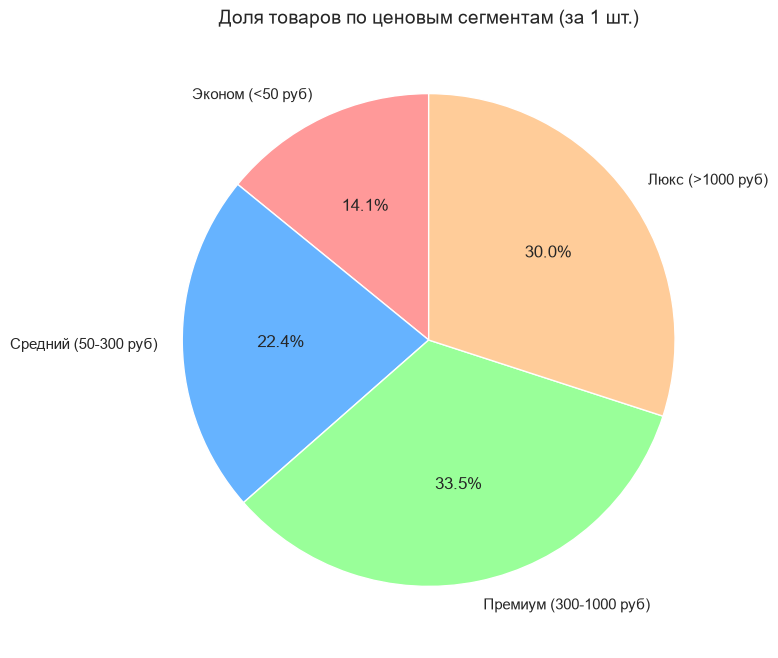

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стиля для красивых графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# ==========================================
# 1. Круговая диаграмма (Доли сегментов)
# ==========================================
plt.figure(figsize=(8, 8))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
plt.pie(segment_stats_final['count'], 
        labels=segment_stats_final['segment'], 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors, 
        wedgeprops={'edgecolor': 'white'})
plt.title('Доля товаров по ценовым сегментам (за 1 шт.)', fontsize=14)
plt.show()

# ==========================================
# 2. Сохранение в Excel
# ==========================================
try:
    import openpyxl
except ImportError:
    import sys
    !{sys.executable} -m pip install openpyxl
    import openpyxl

# Подготовим данные для выгрузки
df_export = df_final[[
    'id', 'name', 'price', 'qty_in_pack', 'price_per_item', 
    'description_category_id', 'segment'
]].copy()

# Переименуем колонки на русский для удобства HR
df_export.columns = [
    'ID товара', 'Название', 'Цена за упаковку (руб)', 'Кол-во в упаковке (шт)', 
    'Цена за 1 шт (руб)', 'ID категории', 'Ценовой сегмент'
]

# Отсортируем от самых дорогих к дешевым
df_export = df_export.sort_values('Цена за 1 шт (руб)', ascending=False)

filename = 'Ozon_Анализ_Пакеты_бумажные_FINAL.xlsx'

with pd.ExcelWriter(filename, engine='openpyxl') as writer:
    # Лист 1: Детальные данные по каждому пакету
    df_export.to_excel(writer, sheet_name='Детальные данные', index=False)
    
    # Лист 2: Сводная таблица по сегментам
    segment_stats_final.to_excel(writer, sheet_name='Сводка по сегментам', index=False)


In [23]:
# Топ-10 самых дорогих за 1 шт
print("ТОП-10 САМЫХ ДОРОГИХ (за 1 шт):")
print(df_final.nlargest(10, 'price_per_item')[['name', 'price', 'qty_in_pack', 'price_per_item']].to_string(index=False))

print("\nТОП-10 САМЫХ ДЕШЕВЫХ (за 1 шт):")
print(df_final.nsmallest(10, 'price_per_item')[['name', 'price', 'qty_in_pack', 'price_per_item']].to_string(index=False))

ТОП-10 САМЫХ ДОРОГИХ (за 1 шт):
                                                                                                             name   price  qty_in_pack  price_per_item
                  10 шт. Крафт пакет с воздушной подушкой 110х160 мм, белый. Пакет с пупыркой A/000, Драйв Директ 49680.0           10          4968.0
Подарочный пакет 22х10х35 см черный с веревочными ручками, 2 шт, блестящий бумажный подарочный пакет Драйв Директ  7223.0            2          3611.5
                                                Пакет 2 шт.Toptwist голуб крафт, круч. ручки,400х450х160 арт.61/2  7025.0            2          3512.5
                                Пакет 2 шт.Toptwist бордовый, ребреный крафт, крученые ручки,400х450х160 арт.60/2  7025.0            2          3512.5
                                       Пакет Toptwist бордовый, ребреный крафт, крученые ручки,240х310х110 арт.60  3267.0            1          3267.0
                                                         Пакет

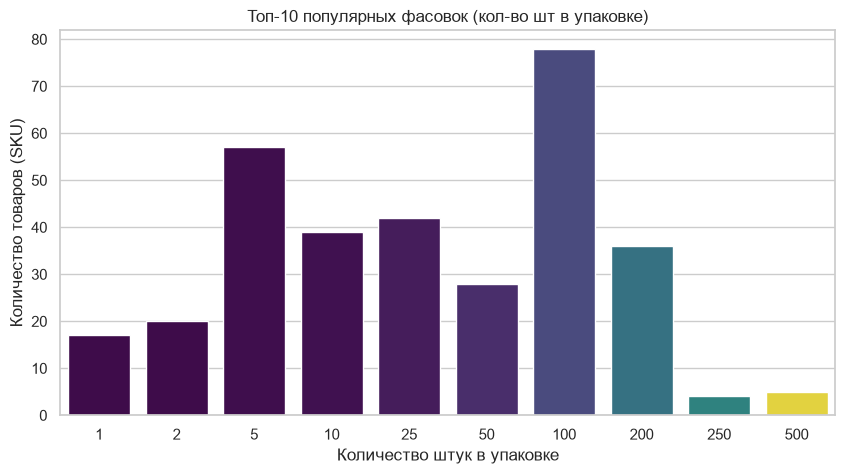

In [29]:
plt.figure(figsize=(10, 5))
qty_counts = df_final['qty_in_pack'].value_counts().head(10)

# Исправленная строка: добавляем hue=x и legend=False
sns.barplot(x=qty_counts.index, y=qty_counts.values, hue=qty_counts.index, palette='viridis', legend=False)

plt.title('Топ-10 популярных фасовок (кол-во шт в упаковке)')
plt.xlabel('Количество штук в упаковке')
plt.ylabel('Количество товаров (SKU)')
plt.show()

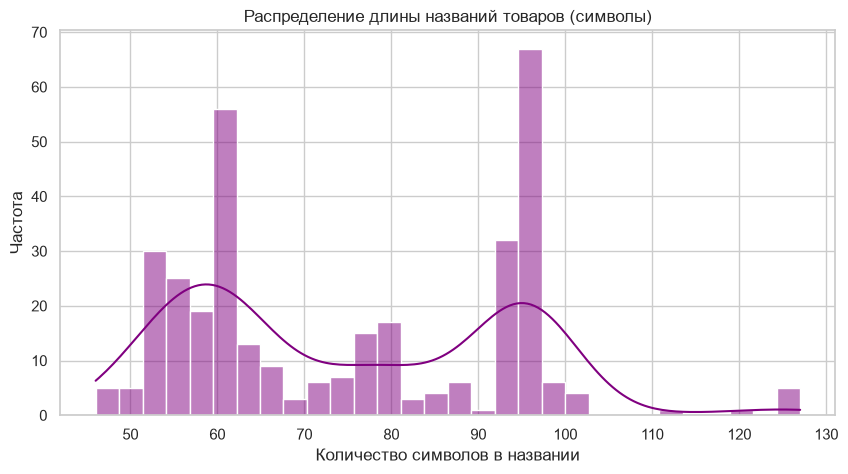

Средняя длина названия: 75.1 символов


In [25]:
df_final['name_length'] = df_final['name'].str.len()

plt.figure(figsize=(10, 5))
sns.histplot(df_final['name_length'], bins=30, kde=True, color='purple')
plt.title('Распределение длины названий товаров (символы)')
plt.xlabel('Количество символов в названии')
plt.ylabel('Частота')
plt.show()

print(f"Средняя длина названия: {df_final['name_length'].mean():.1f} символов")

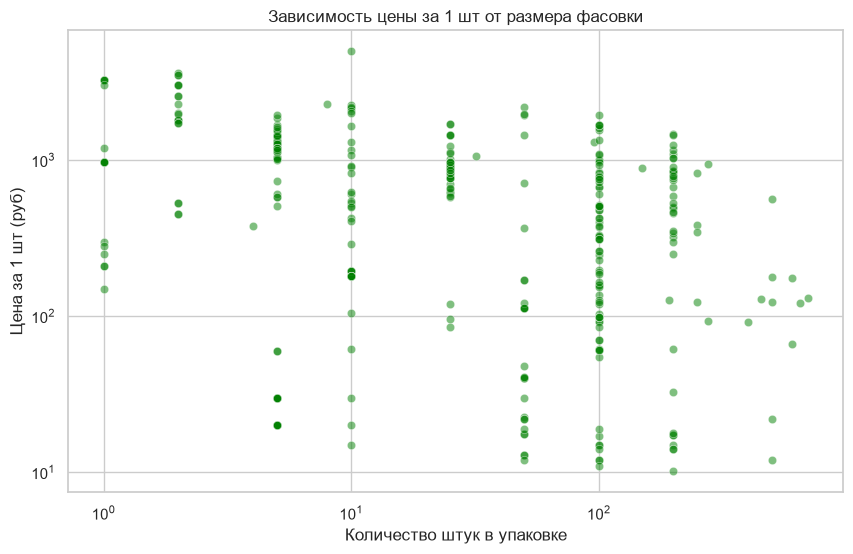

In [26]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='qty_in_pack', y='price_per_item', data=df_final, alpha=0.5, color='green')
plt.title('Зависимость цены за 1 шт от размера фасовки')
plt.xlabel('Количество штук в упаковке')
plt.ylabel('Цена за 1 шт (руб)')
plt.xscale('log')
plt.yscale('log')
plt.show()

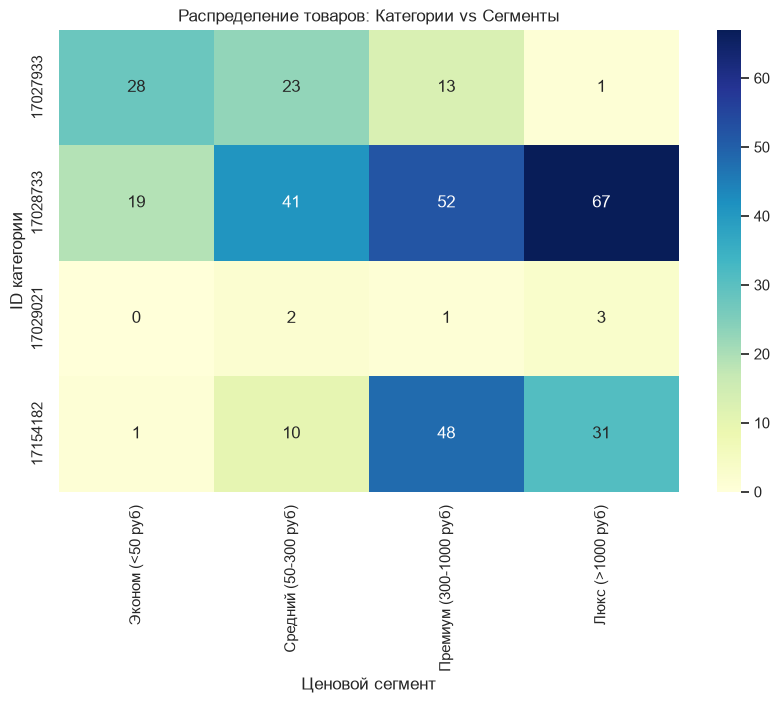

In [27]:
cross_tab = pd.crosstab(df_final['description_category_id'], df_final['segment'])
plt.figure(figsize=(10, 6))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Распределение товаров: Категории vs Сегменты')
plt.xlabel('Ценовой сегмент')
plt.ylabel('ID категории')
plt.show()

In [28]:
pivot_qty = df_final.groupby('qty_in_pack').agg(
    count=('id', 'count'),
    avg_pack_price=('price', 'mean'),
    avg_item_price=('price_per_item', 'mean')
).sort_values('count', ascending=False).head(10)

print("СТАТИСТИКА ПО ПОПУЛЯРНЫМ ФАСОВКАМ:")
print(pivot_qty.to_string())

СТАТИСТИКА ПО ПОПУЛЯРНЫМ ФАСОВКАМ:
             count  avg_pack_price  avg_item_price
qty_in_pack                                       
100             78    46564.743590      465.647436
5               57     4699.245614      939.849123
25              42    22091.309524      883.652381
10              39     7794.230769      779.423077
200             36   113788.083333      568.940417
50              28    17694.107143      353.882143
2               20     4194.500000     2097.250000
1               17     1385.529412     1385.529412
500              5    89814.200000      179.628400
250              4   104903.000000      419.612000
